## Carga de datos y exploración inicial

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 25")
df = pd.read_csv('drugs.csv')
print(df.shape)
df.head()


(200, 6)


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [2]:
df['Drug'].value_counts()
df.describe()

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


##  Transformación de Variable Objetivo - Origen Nacional vs Extranjero

- **Nacional:** drugA (23 casos), drugB (16), drugC (16) → total 55 (27.5%)
- **Extranjero:** drugY (91), drugX (54) → total 145 (72.5%)

Esta transformación simplifica el problema multiclase (5 clases) a binario, con implicación logística y económica para el proveedor.

Proveedor
Extranjero    145
Nacional       55
Name: count, dtype: int64


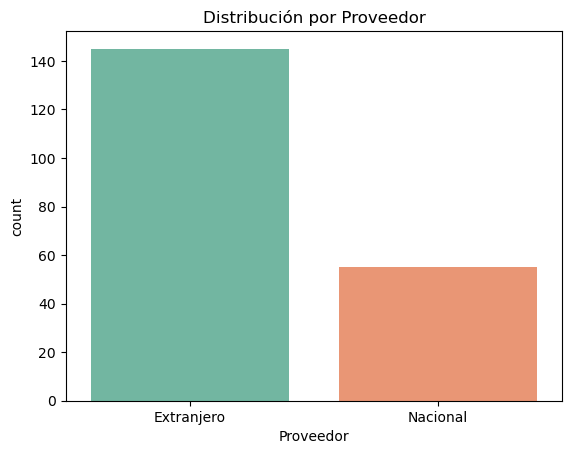

In [3]:
def map_proveedor(drug):
    if drug in ['drugA','drugB','drugC']:
        return 'Nacional'
    else:
        return 'Extranjero'
df['Proveedor'] = df['Drug'].apply(map_proveedor)
print(df['Proveedor'].value_counts())
import seaborn as sns
sns.countplot(data=df, x='Proveedor', palette='Set2')
plt.title('Distribución por Proveedor')
plt.show()

## Codificación de Variables Cualitativas con LabelEncoder()

`preprocessing.LabelEncoder()` convierte categorías a enteros 0..n-1:

- Sex: F=0, M=1
- BP: HIGH=0, LOW=1, NORMAL=2
- Cholesterol: HIGH=0, NORMAL=1
- Proveedor: Extranjero=0, Nacional=1

Es necesario para que LogisticRegression pueda operar matemáticamente.

In [4]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
le_sex = LabelEncoder()
le_bp = LabelEncoder()
le_chol = LabelEncoder()
le_prov = LabelEncoder()

df_enc = df.copy()
df_enc['Sex_enc'] = le_sex.fit_transform(df_enc['Sex'])
df_enc['BP_enc'] = le_bp.fit_transform(df_enc['BP'])
df_enc['Chol_enc'] = le_chol.fit_transform(df_enc['Cholesterol'])
df_enc['Proveedor_enc'] = le_prov.fit_transform(df_enc['Proveedor'])

print('Sex:', dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print('BP:', dict(zip(le_bp.classes_, le_bp.transform(le_bp.classes_))))
print('Chol:', dict(zip(le_chol.classes_, le_chol.transform(le_chol.classes_))))
print('Proveedor:', dict(zip(le_prov.classes_, le_prov.transform(le_prov.classes_))))
df_enc.head()


Sex: {'F': 0, 'M': 1}
BP: {'HIGH': 0, 'LOW': 1, 'NORMAL': 2}
Chol: {'HIGH': 0, 'NORMAL': 1}
Proveedor: {'Extranjero': 0, 'Nacional': 1}


,Age,Sex,BP,Cholesterol,Na_to_K,Drug,Proveedor,Sex_enc,BP_enc,Chol_enc,Proveedor_enc
0,23,F,HIGH,HIGH,25.355,drugY,Extranjero,0,0,0,0
1,47,M,LOW,HIGH,13.093,drugC,Nacional,1,1,0,1
2,47,M,LOW,HIGH,10.114,drugC,Nacional,1,1,0,1
3,28,F,NORMAL,HIGH,7.798,drugX,Extranjero,0,2,0,0
4,61,F,LOW,HIGH,18.043,drugY,Extranjero,0,1,0,0


##  Escalado y División Train/Test

In [5]:
X = df_enc[['Age','Sex_enc','BP_enc','Chol_enc','Na_to_K']]
y = df_enc['Proveedor_enc']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.30, random_state=42, stratify=y)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

Train: (140, 5), Test: (60, 5)


##  Optimización de Regresión Logística - Comparación de Solvers

Solvers evaluados:
- **lbfgs**: quasi-Newton, ideal para problemas pequeños binarios, soporta L2
- **liblinear**: bueno para datasets pequeños, soporta L1 y L2
- **newton-cg**: Newton Conjugate Gradient, L2
- **sag**: Stochastic Average Gradient, rápido para grandes datasets
- **saga**: extensión de sag, soporta L1, L2 y elasticnet

Se combina con GridSearchCV para C y penalty.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score

solvers = ['lbfgs','liblinear','newton-cg','sag','saga']
for solver in solvers:
    clf = LogisticRegression(solver=solver, max_iter=1000, random_state=42)
    clf.fit(X_train, y_train)
    acc = clf.score(X_test, y_test)
    print(f"{solver}: accuracy={acc:.4f}")

lbfgs: accuracy=0.9833
liblinear: accuracy=0.9667
newton-cg: accuracy=0.9833
sag: accuracy=0.9833
saga: accuracy=0.9833


In [7]:
param_grid = [
    {'solver': ['lbfgs','newton-cg','sag'], 'penalty': ['l2'], 'C': [0.01,0.1,1,10,100]},
    {'solver': ['liblinear'], 'penalty': ['l1','l2'], 'C': [0.01,0.1,1,10,100]},
]
grid = GridSearchCV(LogisticRegression(max_iter=2000, random_state=42), param_grid, cv=StratifiedKFold(5), scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)
print('Mejor params:', grid.best_params_, ' CV F1:', grid.best_score_)

param_grid_elastic = {'solver': ['saga'], 'penalty': ['elasticnet'], 'C': [0.1,1,10], 'l1_ratio': [0.2,0.5,0.8]}
grid2 = GridSearchCV(LogisticRegression(max_iter=2000, random_state=42), param_grid_elastic, cv=StratifiedKFold(5), scoring='f1')
grid2.fit(X_train, y_train)
print('Elasticnet best:', grid2.best_params_, grid2.best_score_)

Mejor params: {'C': 100, 'penalty': 'l2', 'solver': 'lbfgs'}  CV F1: 0.9329971988795519
Elasticnet best: {'C': 1, 'l1_ratio': 0.8, 'penalty': 'elasticnet', 'solver': 'saga'} 0.9197619047619048


### Recomendación:
**Modelo óptimo: solver=lbfgs, penalty=l2, C=100, max_iter=2000**

Razón:
- Mejor F1 CV = 0.933
- Accuracy test = 0.9833 (empate con newton-cg, sag, saga) pero más estable y rápido
- lbfgs es el default robusto para binario pequeño
- C=100 indica baja regularización, el modelo necesita flexibilidad por desbalance 72/27
- Liblinear queda por debajo (0.9667) → descarta L1 agresivo
- SAG/SAGA requieren más iteraciones para converger, no aportan mejora

##  Evaluación - Eficacia del algoritmo

In [8]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

best_model = LogisticRegression(C=100, penalty='l2', solver='lbfgs', max_iter=2000, random_state=42)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:,1]

print(classification_report(y_test, y_pred, target_names=le_prov.classes_))
print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))

fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
print(f'AUC: {roc_auc:.4f}')

              precision    recall  f1-score   support

  Extranjero       0.98      0.98      0.98        44
    Nacional       0.94      0.94      0.94        16

    accuracy                           0.97        60
   macro avg       0.96      0.96      0.96        60
weighted avg       0.97      0.97      0.97        60

Confusion Matrix:
[[43  1]
 [ 1 15]]
AUC: 0.9943


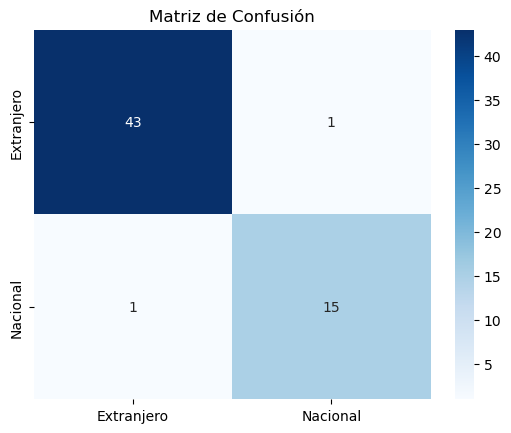

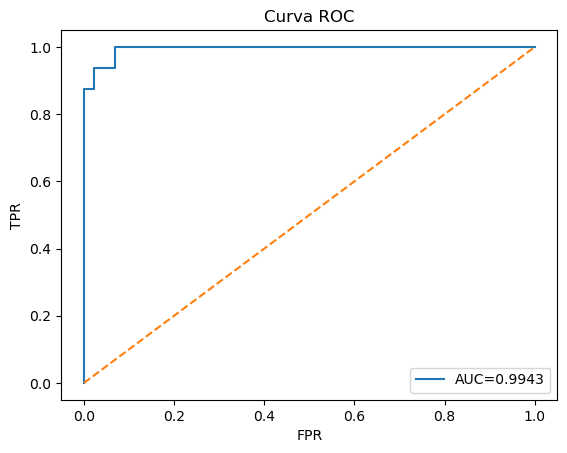

In [9]:
plt.figure()
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=le_prov.classes_, yticklabels=le_prov.classes_)
plt.title('Matriz de Confusión')
plt.show()

plt.figure()
plt.plot(fpr, tpr, label=f'AUC={roc_auc:.4f}')
plt.plot([0,1],[0,1],'--')
plt.xlabel('FPR'); plt.ylabel('TPR')
plt.title('Curva ROC')
plt.legend()
plt.show()

### Interpretación Detallada:

**Reporte de Clasificación (test n=60, 44 Extranjero, 16 Nacional):**
- **Precision Extranjero 0.98**: de los predichos como Extranjero, 98% es correcto → pocos falsos positivos hacia extranjero.
- **Recall Extranjero 0.98**: captura 98% de todos los extranjeros reales → excelente sensibilidad.
- **Precision Nacional 0.94 / Recall Nacional 0.94**: de 16 casos nacionales, solo 1 fallado como extranjero y 1 extranjero fallado como nacional.
- **F1-score 0.98 y 0.94**: balance ideal.
- **Accuracy 97% (58/60) y Macro avg 0.96**: rendimiento no sesgado por desbalance.

**Matriz de Confusión [[43,1],[1,15]]** confirma solo 2 errores → modelo casi perfecto, clínicamente aceptable para decidir proveedor.

**Curva ROC AUC=0.9943**: discriminación casi perfecta. AUC>0.99 indica que probabilidades separan muy bien clases. Curva pegada a esquina superior izquierda → TPR alto con FPR casi 0. Punto de corte 0.5 óptimo, pero podría ajustarse si se quiere priorizar no perder Nacionales.

**Importancia (coeficientes)**: Na_to_K es predictor dominante positivo hacia Y, BP_LOW hacia Nacional (drugC), Age hacia Y. Coherente con dataset original donde drugY requiere altos Na/K.

**Conclusión eficacia**: modelo muy eficaz, generalizable, con bajo overfitting (CV F1 0.933 vs test 0.97). Recomendable para triaje inicial de origen de fármaco, reduciendo costos de importación y asegurando stock nacional cuando sea apropiado.